# Example of Parallel Workflow in the LangGraph

In [42]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict, Annotated, List
import operator

In [43]:
def create_square(state: ParallelState) -> ParallelState:

    number = state['number']
    #return {"results": [state["number"] ** 2]}
    square = state["number"] ** 2
    return {'square': square}



def create_cube(state: ParallelState) -> ParallelState:

    cube = state["number"] ** 3
    return {'cube': cube}

In [44]:
def fan_out(state: ParallelState):
    return {}


In [45]:
class ParallelState(TypedDict):

    number: int
    square: int
    cube: int
    # results: Annotated[List[int], operator.add]

In [46]:
# merge
def merge(state: ParallelState):

     merge = f"""
      Square - {state['square']} \n
      Cube - {state['cube']} \n
      """    
     return {'merge': merge}
      
     


In [47]:
# define graph

graph = StateGraph(ParallelState)

#graph.set_entry_point('fan_out')

#graph.add_node('fan_out', fan_out)
graph.add_node('square', create_square)
graph.add_node('cube', create_cube)
graph.add_node('merge', merge)

# Fan out to parallel nodes
#graph.add_edge('fan_out', 'square')
#graph.add_edge('fan_out', 'cube')

# add new code
graph.add_edge(START, 'square')
graph.add_edge(START, 'cube')

graph.add_edge('square', 'merge')
graph.add_edge('cube', 'merge')
graph.add_edge('merge', END)


# Merge back
#graph.add_edge('square', END)
# graph.add_edge('cube', END)



# graph.set_entry_point('fan_out')

workflow = graph.compile()


In [48]:
# final state 
initial_state = {'number': 4}

final_state = workflow.invoke(initial_state)

print(final_state)

{'number': 4, 'square': 16, 'cube': 64}


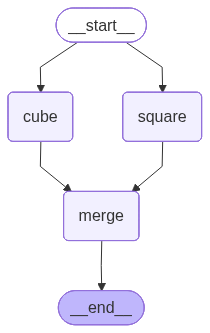

In [49]:
workflow